<a href="https://colab.research.google.com/github/ygonzalesm-jpg/Data_S12_ML_Challenge/blob/main/S14_PCA_Olist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DATA ANALYTICS ML CHALLENGE / 2026-2
## Semana 14. Laboratorio 2. PCA y evaluación de mejoras al modelo
Predicción de entregas tardías en Olist: reducción de dimensionalidad, regularización y contrastes estadísticos.

(ID 16, semilla 1016).

## 1. Carga y preparación de datos (igual que la semana 12)

In [1]:
import hashlib, json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy.stats import ks_2samp
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, average_precision_score, confusion_matrix)

Path('reports').mkdir(exist_ok=True)

In [2]:
ORIGEN = ('https://raw.githubusercontent.com/spdrio/'
          'Brazilian-E-Commerce-Public-Dataset-by-Olist/'
          'fa0cc6d1aff713d3c8b9a1e633b56889881848bf/files')

pedidos = pd.read_csv(f'{ORIGEN}/olist_orders_dataset.csv')
items = pd.read_csv(f'{ORIGEN}/olist_order_items_dataset.csv')
productos = pd.read_csv(f'{ORIGEN}/olist_products_dataset.csv')
clientes = pd.read_csv(f'{ORIGEN}/olist_customers_dataset.csv')
vendedores = pd.read_csv(f'{ORIGEN}/olist_sellers_dataset.csv')
pagos = pd.read_csv(f'{ORIGEN}/olist_order_payments_dataset.csv')
categorias = pd.read_csv(f'{ORIGEN}/product_category_name_translation.csv')
print('Pedidos:', pedidos.shape, '| Items:', items.shape, '| Pagos:', pagos.shape)

Pedidos: (99441, 8) | Items: (112650, 7) | Pagos: (103886, 5)


In [3]:
items = items.merge(productos, on='product_id', how='left', validate='many_to_one')
items = items.merge(vendedores, on='seller_id', how='left', validate='many_to_one')
items = items.merge(categorias, on='product_category_name', how='left', validate='many_to_one')

items['volumen_cm3'] = (items['product_length_cm'] * items['product_height_cm']
                       * items['product_width_cm'])
items['categoria'] = items['product_category_name_english'].fillna(
    items['product_category_name']).fillna('sin_categoria')

resumen_items = items.groupby('order_id', as_index=False).agg(
    valor_productos=('price', 'sum'),
    valor_flete=('freight_value', 'sum'),
    precio_maximo=('price', 'max'),
    cantidad_items=('order_item_id', 'count'),
    cantidad_productos=('product_id', 'nunique'),
    cantidad_vendedores=('seller_id', 'nunique'),
    peso_total_g=('product_weight_g', 'sum'),
    peso_maximo_g=('product_weight_g', 'max'),
    volumen_total_cm3=('volumen_cm3', 'sum'),
    fotos_promedio=('product_photos_qty', 'mean'),
    descripcion_promedio=('product_description_lenght', 'mean'),
    nombre_promedio=('product_name_lenght', 'mean'),
)

principal = (items.sort_values(['order_id', 'price', 'order_item_id'],
                                ascending=[True, False, True])
             .drop_duplicates('order_id'))
principal = principal[['order_id', 'categoria', 'seller_state', 'seller_city']]
principal = principal.rename(columns={
    'categoria': 'categoria_principal',
    'seller_state': 'estado_vendedor',
    'seller_city': 'ciudad_vendedor'
})

resumen_pagos = pagos.groupby('order_id', as_index=False).agg(
    numero_pagos=('payment_sequential', 'count'),
    cuotas_maximas=('payment_installments', 'max'),
    valor_pagado=('payment_value', 'sum'),
)
pago_principal = (pagos.sort_values(['order_id', 'payment_value'],
                                    ascending=[True, False])
                  .drop_duplicates('order_id'))
pago_principal = pago_principal[['order_id', 'payment_type']].rename(
    columns={'payment_type': 'tipo_pago_principal'})

data = pedidos.merge(clientes[['customer_id', 'customer_state', 'customer_city']],
                     on='customer_id', how='inner', validate='one_to_one')
data = data.merge(resumen_items, on='order_id', how='inner', validate='one_to_one')
data = data.merge(principal, on='order_id', how='left', validate='one_to_one')
data = data.merge(resumen_pagos, on='order_id', how='left', validate='one_to_one')
data = data.merge(pago_principal, on='order_id', how='left', validate='one_to_one')
assert data['order_id'].is_unique, 'Hay pedidos duplicados después de las uniones.'
print('Pedidos integrados:', len(data))

Pedidos integrados: 98666


In [4]:
fechas = ['order_purchase_timestamp', 'order_estimated_delivery_date',
          'order_delivered_customer_date']
for columna in fechas:
    data[columna] = pd.to_datetime(data[columna], errors='coerce')

data = data.loc[data['order_status'] == 'delivered'].dropna(subset=fechas).copy()
compra = data['order_purchase_timestamp'].dt.normalize()
prevista = data['order_estimated_delivery_date'].dt.normalize()
real = data['order_delivered_customer_date'].dt.normalize()

data['dias_prometidos'] = (prevista - compra).dt.days
data['dias_entrega'] = (real - compra).dt.days
data['is_late'] = (real > prevista).astype(int)
data['mes_compra'] = compra.dt.month
data['dia_semana_compra'] = compra.dt.dayofweek
data['dia_mes_compra'] = compra.dt.day
data['hora_compra'] = data['order_purchase_timestamp'].dt.hour
data['compra_fin_semana'] = (data['dia_semana_compra'] >= 5).astype(int)

data['vendedor_mismo_estado'] = (data['customer_state'] == data['estado_vendedor']).astype(int)
data['vendedor_misma_ciudad'] = (
    data['vendedor_mismo_estado'].eq(1) &
    data['customer_city'].str.lower().eq(data['ciudad_vendedor'].str.lower())
).astype(int)
data['proporcion_flete'] = data['valor_flete'] / (
    data['valor_productos'] + data['valor_flete']).replace(0, np.nan)

data = data.loc[(data['dias_prometidos'] >= 0) & (data['dias_entrega'] >= 0)].copy()
data = data.sort_values('order_id').reset_index(drop=True)
print('Pedidos disponibles:', len(data), '| Tardías:', round(100 * data['is_late'].mean(), 2), '%')

Pedidos disponibles: 96470 | Tardías: 6.77 %


In [5]:
columnas_numericas = [
    'dias_prometidos', 'mes_compra', 'dia_semana_compra',
    'dia_mes_compra', 'hora_compra', 'compra_fin_semana',
    'valor_productos', 'valor_flete', 'precio_maximo',
    'cantidad_items', 'cantidad_productos', 'cantidad_vendedores',
    'peso_total_g', 'peso_maximo_g', 'volumen_total_cm3',
    'fotos_promedio', 'descripcion_promedio', 'nombre_promedio',
    'numero_pagos', 'cuotas_maximas', 'valor_pagado',
    'vendedor_mismo_estado', 'vendedor_misma_ciudad', 'proporcion_flete'
]
columnas_categoricas = ['customer_state', 'estado_vendedor',
                        'categoria_principal', 'tipo_pago_principal']
columnas = columnas_numericas + columnas_categoricas

ID_ESTUDIANTE = 16
semilla = 1000 + ID_ESTUDIANTE
identificador = f'{ID_ESTUDIANTE:02d}'

muestra, _ = train_test_split(data, train_size=35000, random_state=semilla,
                              stratify=data['is_late'])
muestra = muestra.sort_values('order_id').reset_index(drop=True)
train, temporal = train_test_split(muestra, test_size=0.30, random_state=semilla,
                                   stratify=muestra['is_late'])
valid, test = train_test_split(temporal, test_size=0.50, random_state=semilla,
                               stratify=temporal['is_late'])

X_train, y_train = train[columnas], train['is_late']
X_valid, y_valid = valid[columnas], valid['is_late']
huella_muestra = hashlib.sha256('|'.join(muestra['order_id']).encode()).hexdigest()[:12]

assert (len(muestra), len(train), len(valid), len(test)) == (35000, 24500, 5250, 5250)
print('ID:', identificador, '| Semilla:', semilla, '| Huella:', huella_muestra)
print('Train:', len(train), '| Valid:', len(valid), '| Test (reservado):', len(test))

ID: 16 | Semilla: 1016 | Huella: 44b677b70804
Train: 24500 | Valid: 5250 | Test (reservado): 5250


## 2. Actividad 1. PCA y varianza explicada acumulada
Imputación (mediana) y estandarización se **ajustan solo con entrenamiento**; luego se ajusta PCA sobre las variables numéricas. Se conserva el mínimo de componentes con varianza acumulada ≥ 90 %.

Variables numéricas iniciales: 24
Componentes para >= 90 % de varianza: 15
Varianza acumulada con 15 componentes: 0.9062
CP1: 0.1937 | CP2: 0.0957


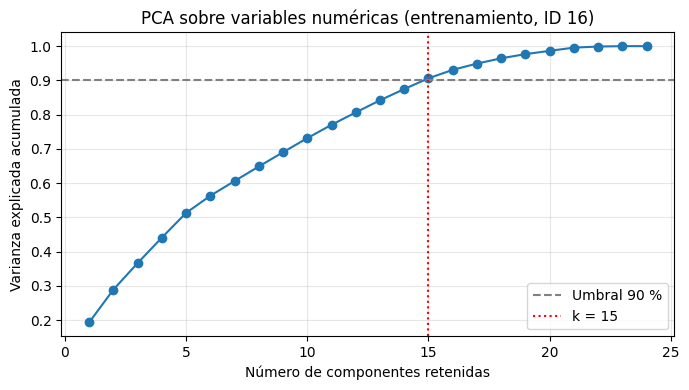

In [6]:
prep_num = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
Z_train = prep_num.fit_transform(X_train[columnas_numericas])

pca_full = PCA(svd_solver='full').fit(Z_train)
acumulada = pca_full.explained_variance_ratio_.cumsum()
n_numericas = len(columnas_numericas)
k = int(np.argmax(acumulada >= 0.90)) + 1

print('Variables numéricas iniciales:', n_numericas)
print('Componentes para >= 90 % de varianza:', k)
print('Varianza acumulada con', k, 'componentes:', round(float(acumulada[k-1]), 4))
print('CP1:', round(float(pca_full.explained_variance_ratio_[0]), 4),
      '| CP2:', round(float(pca_full.explained_variance_ratio_[1]), 4))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, n_numericas + 1), acumulada, marker='o')
ax.axhline(0.90, color='gray', linestyle='--', label='Umbral 90 %')
ax.axvline(k, color='red', linestyle=':', label=f'k = {k}')
ax.set_xlabel('Número de componentes retenidas')
ax.set_ylabel('Varianza explicada acumulada')
ax.set_title('PCA sobre variables numéricas (entrenamiento, ID 16)')
ax.legend(); ax.grid(alpha=.3)
fig.tight_layout()
fig.savefig('reports/S14_varianza_acumulada_ID_16.png', dpi=150)
plt.show()

In [7]:
# Variables con mayor peso (valor absoluto) en las primeras componentes
pesos = pd.DataFrame(pca_full.components_[:3].T, index=columnas_numericas,
                     columns=['CP1', 'CP2', 'CP3'])
for cp in ['CP1', 'CP2', 'CP3']:
    print(cp, '->', pesos[cp].abs().sort_values(ascending=False).head(4).round(3).to_dict())

CP1 -> {'valor_pagado': 0.404, 'valor_productos': 0.387, 'precio_maximo': 0.354, 'peso_total_g': 0.354}
CP2 -> {'proporcion_flete': 0.373, 'precio_maximo': 0.347, 'cantidad_items': 0.335, 'cantidad_productos': 0.312}
CP3 -> {'vendedor_mismo_estado': 0.505, 'dias_prometidos': 0.475, 'vendedor_misma_ciudad': 0.355, 'cantidad_productos': 0.336}


## 3. Actividad 2. Comparación de los cuatro modelos (A–D)
Misma muestra, misma partición, umbral 0,50 y `class_weight='balanced'`. Solo cambian PCA y C.

In [8]:
def construir(usar_pca, C):
    numerica = [SimpleImputer(strategy='median'), StandardScaler()]
    if usar_pca:
        numerica.append(PCA(n_components=k, svd_solver='full'))
    prep = ColumnTransformer([
        ('numericas', make_pipeline(*numerica), columnas_numericas),
        ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                      OneHotEncoder(handle_unknown='ignore')),
         columnas_categoricas),
    ])
    return make_pipeline(prep, LogisticRegression(C=C, class_weight='balanced',
                                                  max_iter=1000))

experimentos = {
    'A. Sin PCA, C=1.0':      dict(usar_pca=False, C=1.0),
    'B. PCA 90 %, C=1.0':     dict(usar_pca=True,  C=1.0),
    'C. PCA 90 %, C=0.1':     dict(usar_pca=True,  C=0.1),
    'D. PCA 90 %, C=10.0':    dict(usar_pca=True,  C=10.0),
}

filas = []
for nombre, cfg in experimentos.items():
    modelo = construir(**cfg).fit(X_train, y_train)
    pred = modelo.predict(X_valid)
    proba = modelo.predict_proba(X_valid)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_valid, pred).ravel()
    filas.append({
        'experimento': nombre, 'accuracy': accuracy_score(y_valid, pred),
        'precision': precision_score(y_valid, pred, zero_division=0),
        'recall': recall_score(y_valid, pred, zero_division=0),
        'f1': f1_score(y_valid, pred, zero_division=0),
        'ap': average_precision_score(y_valid, proba),
        'VP': tp, 'FP': fp, 'FN': fn, 'VN': tn,
        'costo_brl': 8 * fp + 35 * fn,
    })

resultados = pd.DataFrame(filas).set_index('experimento')
resultados.round(4)

,accuracy,precision,recall,f1,ap,VP,FP,FN,VN,costo_brl
experimento,,,,,,,,,,
"A. Sin PCA, C=1.0",0.6787,0.1182,0.5787,0.1963,0.1553,206,1537,150,3357,17546
"B. PCA 90 %, C=1.0",0.6577,0.1048,0.5365,0.1753,0.1224,191,1632,165,3262,18831
"C. PCA 90 %, C=0.1",0.6600,0.1050,0.5337,0.1755,0.1217,190,1619,166,3275,18762
"D. PCA 90 %, C=10.0",0.6573,0.1051,0.5393,0.1759,0.1220,192,1635,164,3259,18820


## 4. Actividad 3. Falsos positivos, falsos negativos y costo didáctico
Supuesto del reto: R$ 8 por FP y R$ 35 por FN (no son costos reales de Olist).

                      VP    FP   FN    VN  costo_brl  costo_FP  costo_FN  \
experimento                                                                
A. Sin PCA, C=1.0    206  1537  150  3357      17546     12296      5250   
B. PCA 90 %, C=1.0   191  1632  165  3262      18831     13056      5775   
C. PCA 90 %, C=0.1   190  1619  166  3275      18762     12952      5810   
D. PCA 90 %, C=10.0  192  1635  164  3259      18820     13080      5740   

                     dif_costo_vs_A  
experimento                          
A. Sin PCA, C=1.0                 0  
B. PCA 90 %, C=1.0             1285  
C. PCA 90 %, C=0.1             1216  
D. PCA 90 %, C=10.0            1274  

Menor costo ilustrativo: A. Sin PCA, C=1.0 -> R$ 17546
Mayor Recall: A. Sin PCA, C=1.0
Mayor F1: A. Sin PCA, C=1.0
Mayor AP: A. Sin PCA, C=1.0
Mayor Accuracy: A. Sin PCA, C=1.0


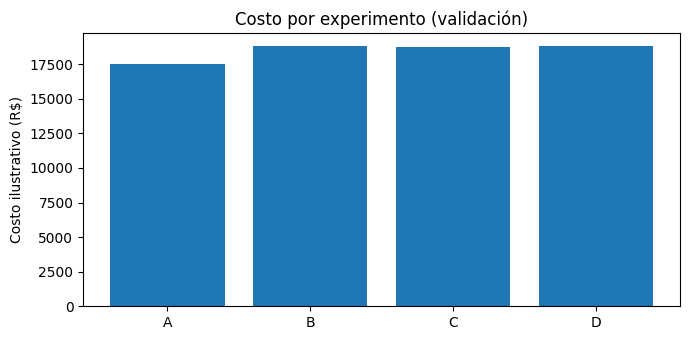

In [9]:
vista = resultados[['VP', 'FP', 'FN', 'VN', 'costo_brl']].copy()
vista['costo_FP'] = 8 * vista['FP']
vista['costo_FN'] = 35 * vista['FN']
vista['dif_costo_vs_A'] = vista['costo_brl'] - vista.loc['A. Sin PCA, C=1.0', 'costo_brl']
print(vista)

mejor = resultados['costo_brl'].idxmin()
print('\nMenor costo ilustrativo:', mejor, '-> R$', resultados.loc[mejor, 'costo_brl'])
print('Mayor Recall:', resultados['recall'].idxmax())
print('Mayor F1:', resultados['f1'].idxmax())
print('Mayor AP:', resultados['ap'].idxmax())
print('Mayor Accuracy:', resultados['accuracy'].idxmax())

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar([n.split('.')[0] for n in resultados.index], resultados['costo_brl'])
ax.set_ylabel('Costo ilustrativo (R$)'); ax.set_title('Costo por experimento (validación)')
fig.tight_layout(); fig.savefig('reports/S14_costos_ID_16.png', dpi=150); plt.show()

## 5. Actividad 4. Kolmogorov-Smirnov sobre `valor_flete` (entrenamiento vs. validación)
H0: `valor_flete` tiene la misma distribución en entrenamiento y validación. H1: las distribuciones son diferentes. α = 0,05.

n entrenamiento: 24500 | n validación: 5250
Estadístico D: 0.01341
Valor p: 0.41426
Decisión (α=0.05): No rechazar H0
       entrenamiento  validación
count       24500.00     5250.00
mean           22.80       22.88
std            23.39       20.08
min             0.00        0.00
25%            13.86       14.06
50%            17.16       17.40
75%            24.00       24.72
max          1794.96      347.56
Valores repetidos (empates) en entrenamiento: 81.1 %


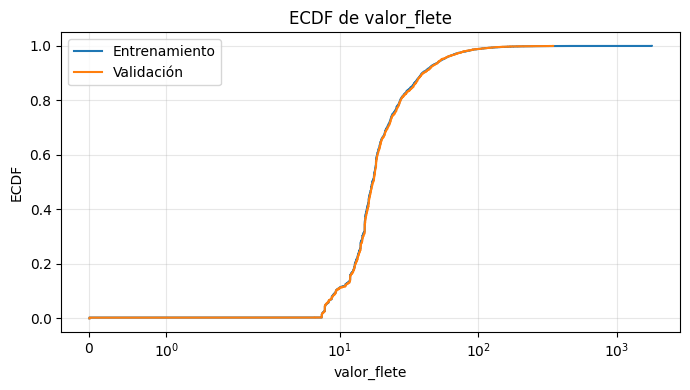

In [10]:
a = train['valor_flete'].dropna()
b = valid['valor_flete'].dropna()
ks = ks_2samp(a, b, alternative='two-sided')
print('n entrenamiento:', len(a), '| n validación:', len(b))
print('Estadístico D:', round(float(ks.statistic), 5))
print('Valor p:', round(float(ks.pvalue), 5))
print('Decisión (α=0.05):', 'Rechazar H0' if ks.pvalue < 0.05 else 'No rechazar H0')

desc = pd.DataFrame({'entrenamiento': a.describe(percentiles=[.25, .5, .75]),
                     'validación': b.describe(percentiles=[.25, .5, .75])})
print(desc.round(2))
print('Valores repetidos (empates) en entrenamiento:',
      round(100 * (1 - a.nunique() / len(a)), 1), '%')

fig, ax = plt.subplots(figsize=(7, 4))
for serie, etiqueta in [(a, 'Entrenamiento'), (b, 'Validación')]:
    x = np.sort(serie.values)
    ax.step(x, np.arange(1, len(x) + 1) / len(x), where='post', label=etiqueta)
ax.set_xscale('symlog'); ax.set_xlabel('valor_flete'); ax.set_ylabel('ECDF')
ax.set_title('ECDF de valor_flete'); ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig('reports/S14_ecdf_flete_ID_16.png', dpi=150); plt.show()

## 6. Registro de resultados

In [12]:
resultados.round(6).to_csv('reports/S14_experimentos_ID_16.csv')

reporte = {
    'laboratorio': 'S14', 'id_estudiante': identificador, 'semilla': semilla,
    'timestamp_utc': pd.Timestamp.now('UTC').isoformat(),
    'python': sys.version.split()[0], 'pandas': pd.__version__,
    'numpy': np.__version__, 'sklearn': sklearn.__version__,
    'n_muestra': len(muestra), 'n_train': len(train), 'n_valid': len(valid),
    'n_test_reservado': len(test), 'huella_muestra': huella_muestra,
    'umbral': 0.5, 'class_weight': 'balanced',
    'pca': {'n_variables_numericas': n_numericas, 'componentes_90pct': k,
            'varianza_acumulada': float(acumulada[k-1])},
    'experimentos': json.loads(resultados.round(6).to_json(orient='index')),
    'modelo_menor_costo': mejor,
    'ks_valor_flete': {'D': float(ks.statistic), 'p_valor': float(ks.pvalue),
                       'n_train': len(a), 'n_valid': len(b), 'alpha': 0.05},
}
ruta = Path(f'reports/S14_resultados_ID_{identificador}.json')
ruta.write_text(json.dumps(reporte, indent=2, ensure_ascii=False), encoding='utf-8')
print('Reporte:', ruta)

# En Colab, descarga el JSON para conservarlo fuera de la sesión.
try:
    from google.colab import files
    files.download(str(ruta))
except Exception:
    print('Si no se descargó automáticamente, guarde manualmente:', ruta)

Reporte: reports/S14_resultados_ID_16.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Interpretación y decisión


**1. PCA.** Había 24 variables numéricas y se necesitaron 15 componentes para explicar al menos el 90 % de la varianza (90,6 %). CP1 explica 19,4 % y CP2 9,6 %: la varianza está repartida, así que las variables son poco redundantes y la reducción es de solo 9 dimensiones (37,5 %). CP1 se asocia sobre todo a `valor_pagado`, `valor_productos`, `precio_maximo` y `peso_total_g` (tamaño y valor del pedido). PCA no usa la variable objetivo: puede descartar direcciones de poca varianza que sí distinguen entregas tardías.


**2. Comparación.** Frente a A (sin PCA), B (PCA, C=1) empeora todas las métricas: Recall 0,579 → 0,537, F1 0,196 → 0,175, AP 0,155 → 0,122 y Accuracy 0,679 → 0,657; los FN suben de 150 a 165. Entre C y D respecto a B las diferencias son mínimas (F1 0,1755 y 0,1739 contra 0,1751; AP 0,122 en los tres), de modo que cambiar la regularización no altera el resultado de forma apreciable. No se puede afirmar que una sea estadísticamente superior: las diferencias son pequeñas y se midieron sobre una sola validación.


**3. Costo y decisión.** Costo ilustrativo (8·FP + 35·FN): A = R 17.530, B = R 18.847, C = R 18.762, D = R 18.922. Se elige **A (sin PCA, C=1,0)**: tiene el menor costo (R 1.232 a 1.392 menos que las configuraciones con PCA), el mayor Recall, F1, AP y Accuracy, y menos FN y FP. La reducción de dimensionalidad no compensó la información perdida. Supuestos: costos didácticos, umbral 0,50 y una sola muestra. Observación adicional: en validación hay 356 pedidos tardíos, y no alertar nunca costaría 35 × 356 = R 12.460, menos que A. La Precision de A (11,8 %) queda por debajo de 8/(8+35) ≈ 18,6 %, el punto en que una alerta empieza a compensar su costo; ajustar el umbral sería un experimento distinto y no se hizo aquí.


**4. Kolmogorov-Smirnov.** H0: `valor_flete` tiene la misma distribución en entrenamiento y validación; H1: son diferentes; α = 0,05. Con n = 24.500 y 5.250, D = 0,0134 y p = 0,414. Como p ≥ 0,05 no se rechaza H0: no hay evidencia suficiente de diferencia entre las particiones (medianas 17,16 y 17,40; cuartiles similares). Esto no demuestra que sean idénticas ni que el modelo esté validado. Limitación: `valor_flete` tiene 81 % de valores repetidos (empates), y la prueba KS supone una variable continua, por lo que el valor p es aproximado.